In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [9]:
import prophet

In [10]:
dir(prophet)

['Path',
 'Prophet',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 '__version__',
 'about',
 'diagnostics',
 'f',
 'forecaster',
 'here',
 'make_holidays',
 'models',
 'plot']

In [11]:
df = pd.read_excel('DATASETS/new_dataset.xlsx')
df.head()

,date,price,exchange rate (1 USD TO TZS),observation
0,2010-01-01,1533.9349,1313.0056,baseline / no prior month
1,2010-02-01,1620.3256,1323.5843,normal month-over-month move
2,2010-03-01,1572.1865,1326.3845,normal month-over-month move
3,2010-04-01,1681.5984,1330.0796,normal month-over-month move
4,2010-05-01,1711.4398,1343.2834,normal month-over-month move


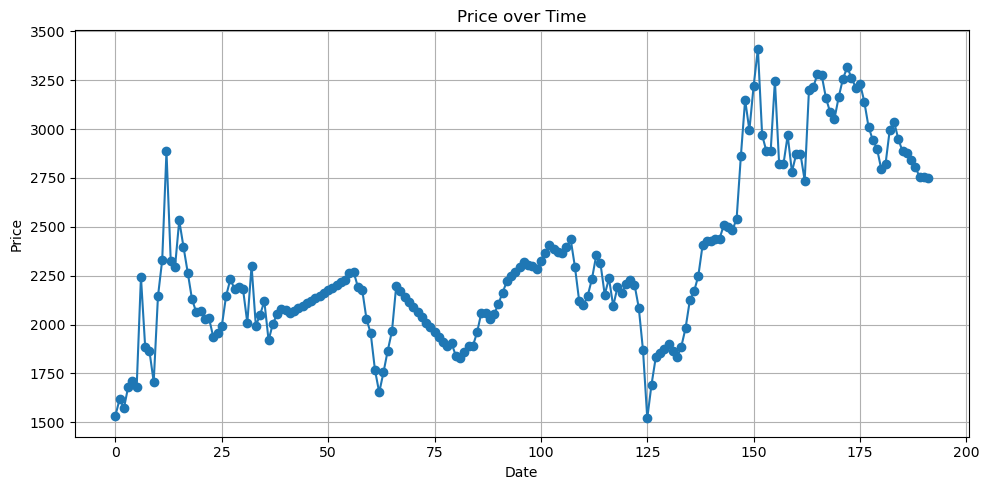

In [12]:
plt.figure(figsize=(10, 5))
plt.plot(df.index, df['price'], marker='o', linestyle='-')
plt.title('Price over Time')
plt.xlabel('Date')
plt.ylabel('Price')
plt.grid(True)
plt.tight_layout()
plt.show()

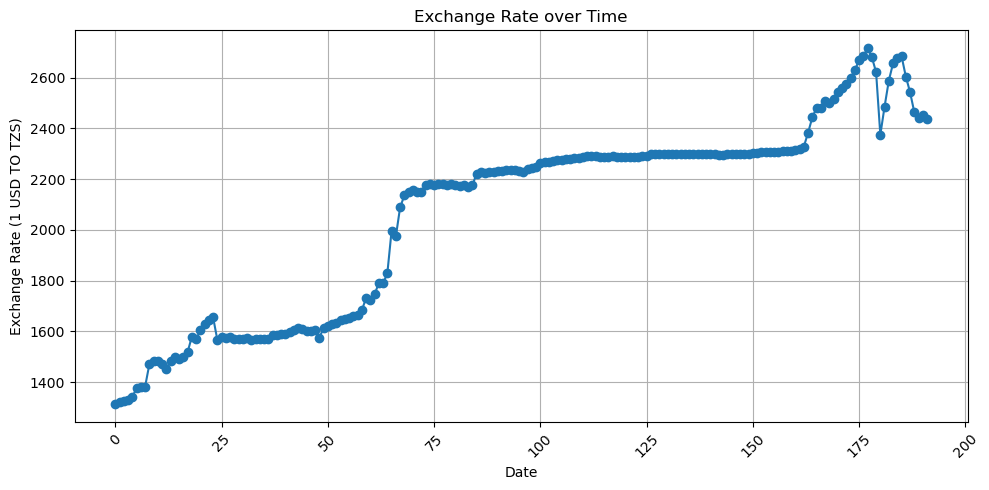

In [13]:

plt.figure(figsize=(10, 5))
plt.plot(df.index, df['exchange rate (1 USD TO TZS)'], marker='o', linestyle='-')
plt.title('Exchange Rate over Time')
plt.xlabel('Date')
plt.ylabel('Exchange Rate (1 USD TO TZS)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
# make data stationary
df['price'] = df['price'] - df['price'].shift(1)

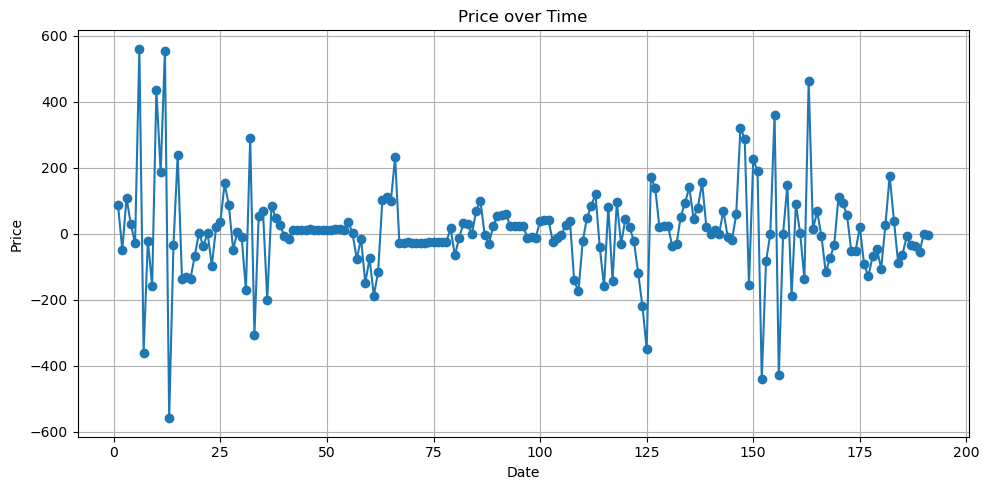

In [15]:
plt.figure(figsize=(10, 5))
plt.plot(df.index, df['price'], marker='o', linestyle='-')
plt.title('Price over Time')
plt.xlabel('Date')
plt.ylabel('Price')
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
from prophet import Prophet

In [17]:
# features of prophet
dir(Prophet)

['__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_load_stan_backend',
 '_logistic_uncertainty',
 '_make_historical_mat_time',
 '_make_trend_shift_matrix',
 '_sample_uncertainty',
 'add_country_holidays',
 'add_group_component',
 'add_regressor',
 'add_seasonality',
 'calculate_initial_params',
 'construct_holiday_dataframe',
 'fit',
 'flat_growth_init',
 'flat_trend',
 'fourier_series',
 'initialize_scales',
 'linear_growth_init',
 'logistic_growth_init',
 'make_all_seasonality_features',
 'make_future_dataframe',
 'make_holiday_features',
 'make_seasonality_features',
 'parse_seasonalit

In [18]:
model = Prophet()

In [19]:
df.columns

Index(['date', 'price', 'exchange rate (1 USD TO TZS)', 'observation'], dtype='object')

In [20]:
df.rename(columns={'price': 'y', 'date': 'ds'}, inplace=True)
df.head()

,ds,y,exchange rate (1 USD TO TZS),observation
0,2010-01-01,NaN,1313.0056,baseline / no prior month
1,2010-02-01,86.3907,1323.5843,normal month-over-month move
2,2010-03-01,-48.1391,1326.3845,normal month-over-month move
3,2010-04-01,109.4119,1330.0796,normal month-over-month move
4,2010-05-01,29.8414,1343.2834,normal month-over-month move


In [21]:
df= df[1:]
df.head()

,ds,y,exchange rate (1 USD TO TZS),observation
1,2010-02-01,86.3907,1323.5843,normal month-over-month move
2,2010-03-01,-48.1391,1326.3845,normal month-over-month move
3,2010-04-01,109.4119,1330.0796,normal month-over-month move
4,2010-05-01,29.8414,1343.2834,normal month-over-month move
5,2010-06-01,-28.8666,1375.3842,normal month-over-month move


In [22]:
model.fit(df)

11:01:42 - cmdstanpy - INFO - Chain [1] start processing
11:01:43 - cmdstanpy - INFO - Chain [1] done processing


In [23]:
df.shape

(191, 4)

In [24]:
future_dates = model.make_future_dataframe(periods=365)

In [25]:
future_dates.shape

(556, 1)

In [26]:
future_dates.head()

,ds
0,2010-02-01
1,2010-03-01
2,2010-04-01
3,2010-05-01
4,2010-06-01


In [27]:
prediction = model.predict(future_dates)

In [28]:
prediction.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2010-02-01,9.232672,-206.347053,139.197846,9.232672,9.232672,-43.119131,-43.119131,-43.119131,-43.119131,-43.119131,-43.119131,0.0,0.0,0.0,-33.886460
1,2010-03-01,9.192444,-140.431272,218.523904,9.192444,9.192444,31.768466,31.768466,31.768466,31.768466,31.768466,31.768466,0.0,0.0,0.0,40.960910
2,2010-04-01,9.147905,-124.437965,234.866267,9.147905,9.147905,47.723059,47.723059,47.723059,47.723059,47.723059,47.723059,0.0,0.0,0.0,56.870964
3,2010-05-01,9.104804,-154.425442,174.686129,9.104804,9.104804,7.487587,7.487587,7.487587,7.487587,7.487587,7.487587,0.0,0.0,0.0,16.592391
4,2010-06-01,9.060265,-202.566656,138.826615,9.060265,9.060265,-30.721682,-30.721682,-30.721682,-30.721682,-30.721682,-30.721682,0.0,0.0,0.0,-21.661417


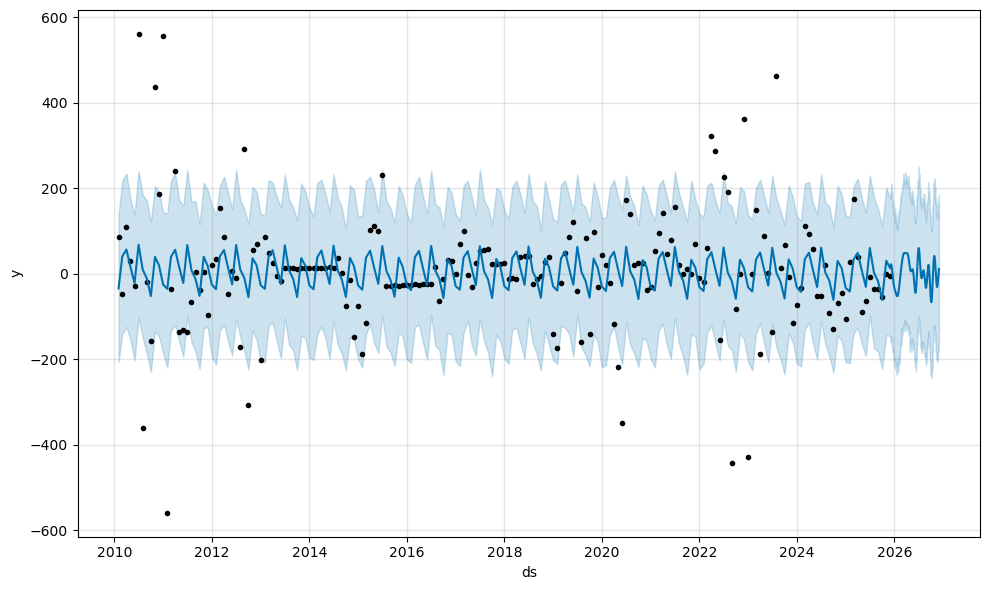

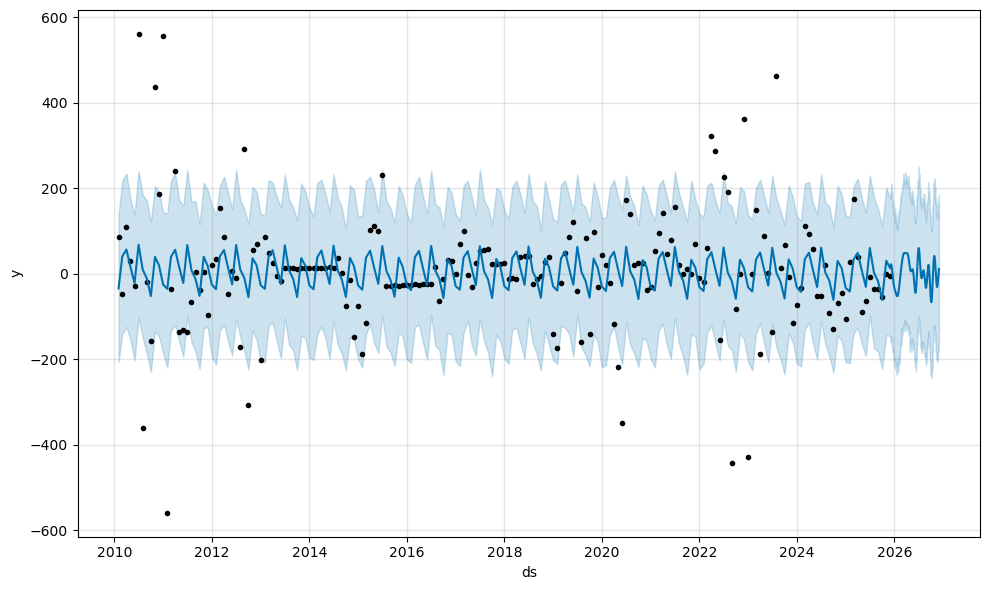

In [29]:
model.plot(prediction)

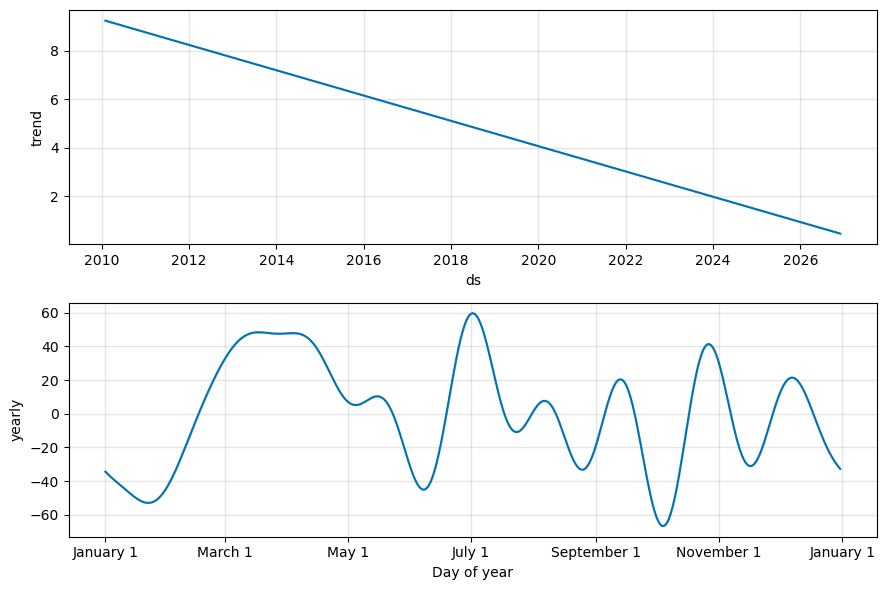

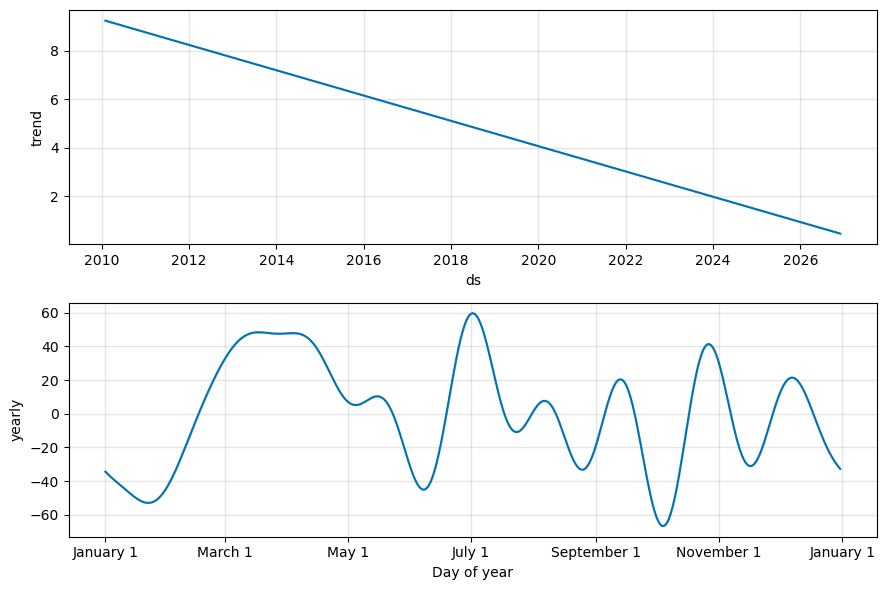

In [30]:
model.plot_components(prediction)

In [31]:
from prophet.diagnostics import cross_validation, performance_metrics


In [32]:
df.shape

(191, 4)

In [33]:
cv = cross_validation(model, initial='191 days', period='180 days', horizon='365 days')

Seasonality has period of 365.25 days which is larger than initial window. Consider increasing initial.
  0%|          | 0/30 [00:00<?, ?it/s]11:15:45 - cmdstanpy - INFO - Chain [1] start processing
11:15:46 - cmdstanpy - INFO - Chain [1] done processing
  3%|▎         | 1/30 [00:01<00:49,  1.72s/it]11:15:47 - cmdstanpy - INFO - Chain [1] start processing
11:15:48 - cmdstanpy - INFO - Chain [1] done processing
  7%|▋         | 2/30 [00:03<00:54,  1.95s/it]11:15:49 - cmdstanpy - INFO - Chain [1] start processing
11:15:51 - cmdstanpy - INFO - Chain [1] done processing
 10%|█         | 3/30 [00:06<01:03,  2.37s/it]11:15:52 - cmdstanpy - INFO - Chain [1] start processing
11:15:52 - cmdstanpy - INFO - Chain [1] done processing
 13%|█▎        | 4/30 [00:07<00:45,  1.76s/it]11:15:53 - cmdstanpy - INFO - Chain [1] start processing
11:15:53 - cmdstanpy - INFO - Chain [1] done processing
 17%|█▋        | 5/30 [00:08<00:39,  1.56s/it]11:15:54 - cmdstanpy - INFO - Chain [1] start processing
11:15:

In [34]:
cv.head()

,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2010-09-01,-17501.136739,-17501.136740,-17501.136738,-20.0387,2010-08-17
1,2010-10-01,1221.960801,1221.960798,1221.960804,-156.7339,2010-08-17
2,2010-11-01,-7677.229873,-7677.229879,-7677.229867,437.2956,2010-08-17
3,2010-12-01,443.229278,443.229268,443.229288,186.1936,2010-08-17
4,2011-01-01,3361.041656,3361.041641,3361.041670,555.2558,2010-08-17


In [35]:
df_pm = performance_metrics(cv)

In [36]:
df_pm

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,37 days,8.774665e+06,2962.206054,637.463782,27.677870,2.022103,1.569012,0.714286
1,41 days,8.774965e+06,2962.256801,639.359084,27.564819,2.462921,1.563277,0.714286
2,42 days,8.773849e+06,2962.068438,635.610151,27.511211,2.462921,1.563277,0.742857
3,43 days,8.773567e+06,2962.020754,634.241516,27.583702,2.564426,1.587057,0.742857
4,45 days,8.827851e+06,2971.169899,672.788916,27.830514,2.565891,1.639299,0.714286
...,...,...,...,...,...,...,...,...
222,359 days,2.204370e+06,1484.711976,472.994672,19.223053,1.662749,1.735196,0.728571
223,360 days,2.180725e+06,1476.727872,463.967075,17.968416,1.662749,1.761479,0.714286
224,362 days,2.164063e+06,1471.075324,448.978290,17.891567,1.662749,1.732463,0.728571
225,364 days,2.148082e+06,1465.633818,437.665756,18.117196,1.642599,1.721695,0.742857


In [37]:
from prophet.plot import plot_cross_validation_metric

c:\ProgramData\anaconda3\envs\datascience\Lib\site-packages\prophet\plot.py:547: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  x_plt = df_none['horizon'].astype('timedelta64[ns]').view(np.int64) / float(dt_conversions[i])
c:\ProgramData\anaconda3\envs\datascience\Lib\site-packages\prophet\plot.py:548: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  x_plt_h = df_h['horizon'].astype('timedelta64[ns]').view(np.int64) / float(dt_conversions[i])


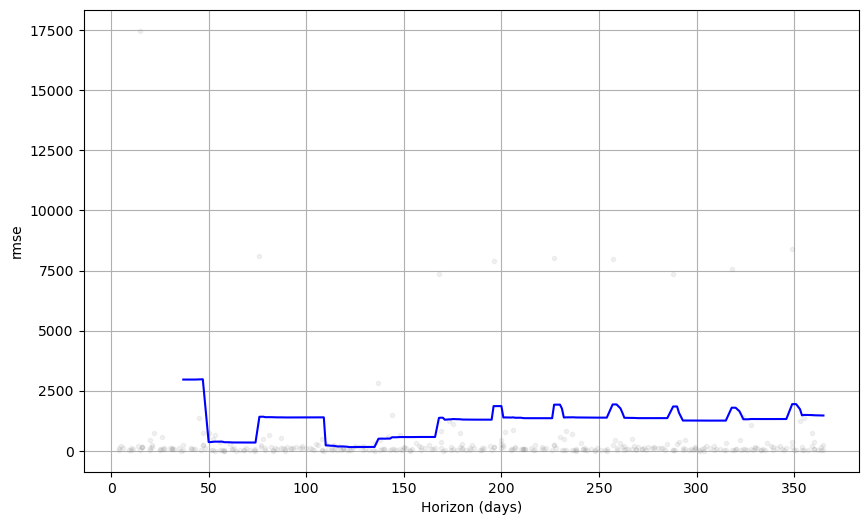

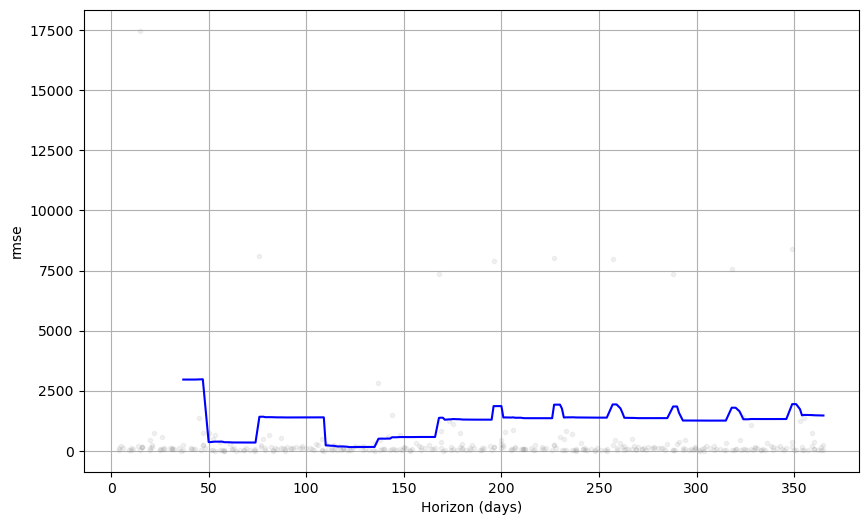

In [38]:
plot_cross_validation_metric(cv, metric='rmse')